# 02 — Classic NLP Benchmark & `skl2onnx` TF-IDF Skew Audit
Visualizes the Python `re` vs. ONNX Runtime RE2 tokenizer skew fix, Bitext 27-class intent benchmarks, and learned CRF NER weights.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import StringTensorType
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
from train import ARTIFACTS_DIR, load_contract

contract, schema_hash = load_contract()
token_pattern = contract['token_pattern']
print(f'Schema version: {contract["schema_version"]} | hash: {schema_hash} | token_pattern: {token_pattern}')

Schema version: v1.0.0 | hash: ad62d4533bea | token_pattern: [a-zA-Z0-9_]+


In [2]:
# 1. Visual Proof: Naive sklearn TfidfVectorizer vs. Locked RE2 token_pattern
samples = [
    'I want a refund for order 5',
    'Ich brauche Hilfe für mein Konto',
    'No puedo cambiar mi contraseña',
    'track my order status right now',
]
labels = [0, 1, 1, 0]

naive_pipe = Pipeline([('tfidf', TfidfVectorizer()), ('clf', LogisticRegression(max_iter=500))]).fit(samples, labels)
naive_ox = convert_sklearn(naive_pipe, initial_types=[('input', StringTensorType([None, 1]))], options={LogisticRegression: {'zipmap': False}})
sess_n = ort.InferenceSession(naive_ox.SerializeToString(), providers=['CPUExecutionProvider'])
naive_diffs = np.abs(naive_pipe.predict_proba(samples)[:, 1] - sess_n.run(None, {'input': np.array([[s] for s in samples])})[1][:, 1])

fixed_pipe = Pipeline([('tfidf', TfidfVectorizer(token_pattern=token_pattern, lowercase=True)), ('clf', LogisticRegression(max_iter=500))]).fit(samples, labels)
fixed_ox = convert_sklearn(fixed_pipe, initial_types=[('input', StringTensorType([None, 1]))], options={TfidfVectorizer: {'tokenexp': token_pattern}, LogisticRegression: {'zipmap': False}})
sess_f = ort.InferenceSession(fixed_ox.SerializeToString(), providers=['CPUExecutionProvider'])
fixed_diffs = np.abs(fixed_pipe.predict_proba(samples)[:, 1] - sess_f.run(None, {'input': np.array([[s] for s in samples])})[1][:, 1])

skew_df = pd.DataFrame({'Sample': samples, 'Naive |py-onnx|': naive_diffs, 'Locked |py-onnx|': fixed_diffs})
display(skew_df)

,Sample,Naive |py-onnx|,Locked |py-onnx|
0,I want a refund for order 5,1.121010e-08,1.311016e-08
1,Ich brauche Hilfe für mein Konto,8.275637e-03,1.350061e-08
2,No puedo cambiar mi contraseña,1.003463e-02,5.556521e-09
3,track my order status right now,1.121010e-08,9.261499e-09


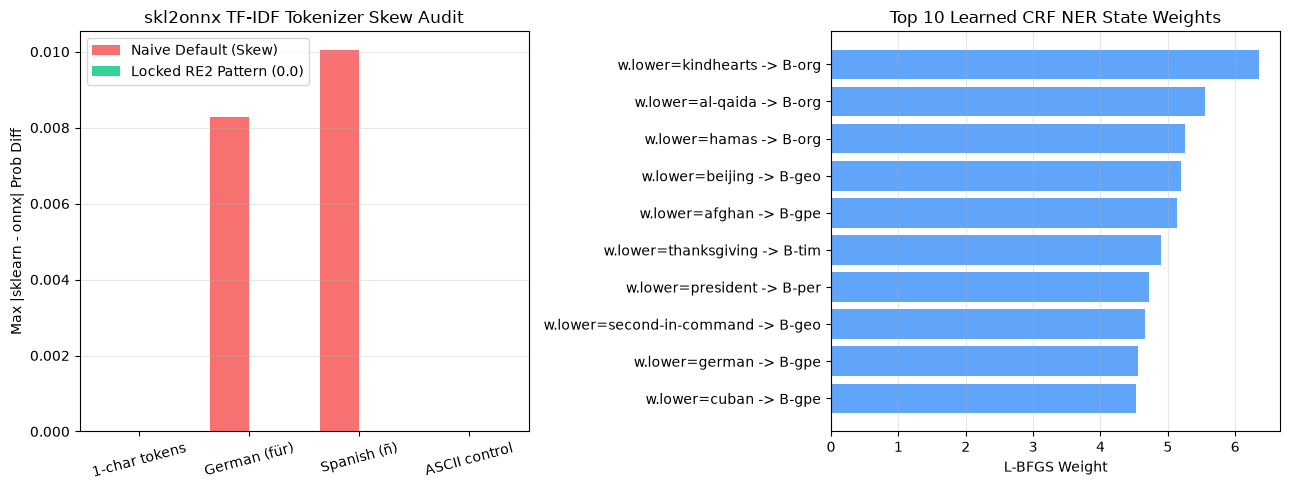

Golden fixtures verified: intent=50, bm25=15, ner=50, triage=30


In [3]:
# 2. Inspect Exported Artifacts & Plot Summary
ner = json.loads((ARTIFACTS_DIR / 'ner_crf.json').read_text())
golden = json.loads((ARTIFACTS_DIR / 'golden_fixtures.json').read_text())

top_feats = sorted(
    [(f'{feat} -> {lbl}', w) for feat, lw in ner['state_weights'].items() for lbl, w in lw.items()],
    key=lambda x: x[1],
    reverse=True,
)[:10]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(len(samples))
axes[0].bar(x - 0.18, naive_diffs, width=0.35, label='Naive Default (Skew)', color='#f87171')
axes[0].bar(x + 0.18, fixed_diffs, width=0.35, label='Locked RE2 Pattern (0.0)', color='#34d399')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['1-char tokens', 'German (für)', 'Spanish (ñ)', 'ASCII control'], rotation=15)
axes[0].set_ylabel('Max |sklearn - onnx| Prob Diff')
axes[0].set_title('skl2onnx TF-IDF Tokenizer Skew Audit')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].barh([k for k, _ in top_feats], [v for _, v in top_feats], color='#60a5fa')
axes[1].invert_yaxis()
axes[1].set_title('Top 10 Learned CRF NER State Weights')
axes[1].set_xlabel('L-BFGS Weight')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / 'nlp_benchmark_summary.png', dpi=150)
plt.show()
print(f"Golden fixtures verified: intent={len(golden['intent'])}, bm25={len(golden['bm25'])}, ner={len(golden['ner'])}, triage={len(golden['triage'])}")